# Sentinel · Análisis de datos

Módulo de análisis del Trabajo Práctico Integrador (punto 5.7 de la consigna). Lee los datos **directamente desde MongoDB**
(base `sentinel`), calcula tres indicadores, los grafica y termina con una recomendación.

**Preguntas del dominio que responde**

1. ¿Qué categorías de incidente incumplen más el SLA de resolución?
2. ¿Cuánto tarda en resolverse cada categoría?
3. ¿El trabajo está repartido de acuerdo con la capacidad de cada agente?

**Decisión que busca informar:** en qué área reforzar al equipo de soporte.

**Cómo ejecutarlo**: con el entorno levantado y los datos cargados (README, secciones 3 y 5):

```bash
pip install -r analisis/requirements.txt
jupyter lab analisis/analisis_sentinel.ipynb
```

## 1. Conexión y recuperación de los datos

In [1]:
import os

import matplotlib.pyplot as plt
import pandas as pd
from matplotlib.patches import Patch
from pymongo import MongoClient

# Desde tu PC MongoDB se publica en localhost:27017 (docker-compose.yml). Si cambiaste MONGO_PORT, definí MONGO_URI.
URI = os.getenv("MONGO_URI", "mongodb://localhost:27017/?directConnection=true")
DB = os.getenv("MONGO_DB", "sentinel")

db = MongoClient(URI, serverSelectionTimeoutMS=3000)[DB]
db.command("ping")          # falla con un error claro si MongoDB no está levantado
print(f"Conectado a '{DB}':", {c: db[c].count_documents({}) for c in ["tickets", "agentes", "categorias", "clientes"]})

Conectado a 'sentinel': {'tickets': 280, 'agentes': 10, 'categorias': 5, 'clientes': 60}


In [2]:
# Se piden a MongoDB solo los campos necesarios (proyección) y se aplanan los subdocumentos con json_normalize.
campos_ticket = {"_id": 0, "numero": 1, "categoria.codigo": 1, "prioridad": 1, "estado": 1, "agente.nombre": 1,
                 "creado": 1, "resuelto_en": 1, "sla.incumplido": 1, "satisfaccion.puntaje": 1}
tickets = pd.json_normalize(list(db.tickets.find({}, campos_ticket))).rename(columns={
    "categoria.codigo": "categoria", "agente.nombre": "agente",
    "sla.incumplido": "incumplido", "satisfaccion.puntaje": "puntaje"})

agentes = pd.DataFrame(list(db.agentes.find(
    {}, {"_id": 0, "nombre": 1, "nivel": 1, "habilidades": 1, "capacidad_maxima": 1, "carga_actual": 1, "activo": 1})))

# ---- Preparación
tickets["creado"] = pd.to_datetime(tickets["creado"])
tickets["resuelto_en"] = pd.to_datetime(tickets["resuelto_en"])      # NaT en los tickets que no se resolvieron
tickets["horas_resolucion"] = (tickets["resuelto_en"] - tickets["creado"]).dt.total_seconds() / 3600

# Los cancelados no cuentan para medir el cumplimiento del SLA (mismo criterio que la consulta Q7).
vigentes = tickets[tickets["estado"] != "cancelado"]
resueltos = tickets[tickets["horas_resolucion"].notna()]

print(f"Tickets: {len(tickets)} | cancelados excluidos del SLA: {len(tickets) - len(vigentes)} | con resolución: {len(resueltos)}")
print(f"Período: {tickets['creado'].min():%Y-%m-%d} a {tickets['creado'].max():%Y-%m-%d}")
tickets["estado"].value_counts().to_frame("tickets").T

Tickets: 280 | cancelados excluidos del SLA: 12 | con resolución: 242
Período: 2026-07-01 a 2026-10-26


estado,cerrado,en_progreso,cancelado,en_espera,asignado
tickets,242,17,12,6,3


## 2. Indicador 1 · Incumplimiento del SLA por categoría

In [3]:
sla = (vigentes.groupby("categoria")
       .agg(total=("numero", "count"), incumplidos=("incumplido", "sum"), satisfaccion_prom=("puntaje", "mean")))
sla["pct_incumplimiento"] = (sla["incumplidos"] / sla["total"] * 100).round(1)
sla["satisfaccion_prom"] = sla["satisfaccion_prom"].round(2)
sla = sla.sort_values("pct_incumplimiento", ascending=False)
sla

,total,incumplidos,satisfaccion_prom,pct_incumplimiento
categoria,,,,
RED_CONEX,69,31,2.44,44.9
HW_FALLA,79,20,4.07,25.3
MANT_EDIL,33,7,4.30,21.2
SW_ACCESO,54,11,4.24,20.4
COMPRAS,33,5,4.19,15.2


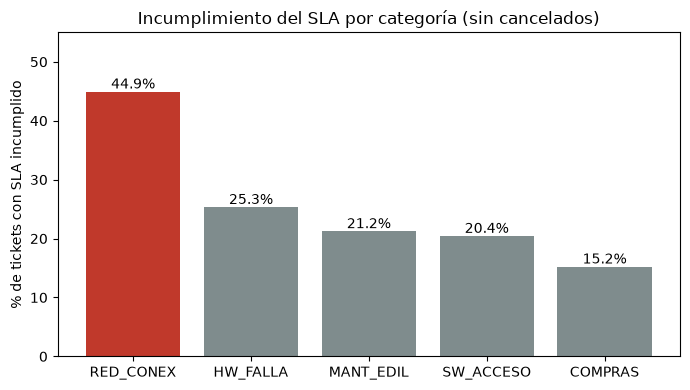

In [4]:
fig, ax = plt.subplots(figsize=(7, 4))
colores = ["#c0392b"] + ["#7f8c8d"] * (len(sla) - 1)           # se resalta la peor categoría
barras = ax.bar(sla.index, sla["pct_incumplimiento"], color=colores)
ax.bar_label(barras, fmt="%.1f%%")
ax.set_ylabel("% de tickets con SLA incumplido")
ax.set_title("Incumplimiento del SLA por categoría (sin cancelados)")
ax.set_ylim(0, 55)
plt.tight_layout()
plt.show()

**Interpretación.** `RED_CONEX` incumple el SLA en 31 de 69 tickets (**44,9 %**), casi el doble que la siguiente (`HW_FALLA`, 25,3 %) y
el triple que `COMPRAS` (15,2 %). Es además la categoría con peor satisfacción: **2,44** sobre 5, frente a valores de 4,07 a 4,30 en
las demás. El problema no es general: se concentra en una categoría.

## 3. Indicador 2 · Tiempo de resolución por categoría

In [5]:
tmr = (resueltos.groupby("categoria")["horas_resolucion"]
       .agg(resueltos="count", media_h="mean", mediana_h="median", max_h="max").round(1)
       .sort_values("media_h", ascending=False))
tmr

,resueltos,media_h,mediana_h,max_h
categoria,,,,
MANT_EDIL,31,36.0,25.1,187.8
COMPRAS,32,34.2,19.5,139.8
HW_FALLA,65,14.0,7.3,54.0
SW_ACCESO,48,8.9,8.4,30.4
RED_CONEX,66,8.5,5.4,31.2


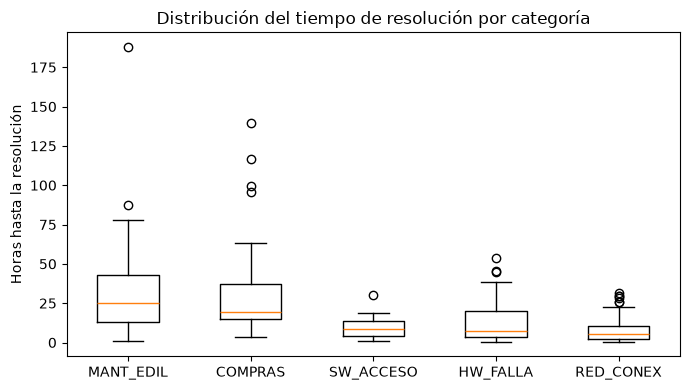

In [6]:
orden = tmr.sort_values("mediana_h", ascending=False).index
datos = [resueltos.loc[resueltos["categoria"] == c, "horas_resolucion"] for c in orden]

fig, ax = plt.subplots(figsize=(7, 4))
ax.boxplot(datos)
ax.set_xticks(range(1, len(orden) + 1))
ax.set_xticklabels(orden)
ax.set_ylabel("Horas hasta la resolución")
ax.set_title("Distribución del tiempo de resolución por categoría")
plt.tight_layout()
plt.show()

**Interpretación.** `MANT_EDIL` (media 36,0 h) y `COMPRAS` (34,2 h) son las categorías más lentas, y en las tres de mayor duración
la media supera a la mediana por varios casos extremos (máximos de 187,8 h y 139,8 h): conviene mirar la mediana. `RED_CONEX` es la
**más rápida** (media 8,5 h, mediana 5,4 h). Entonces, tardar mucho no explica incumplir: `MANT_EDIL` y `COMPRAS` tienen plazos
de 48 h y 72 h para prioridad media, mientras que `RED_CONEX` se compromete a 1, 4, 12 y 24 h según la prioridad. Lo que importa
es la relación entre lo que se tarda y lo que se promete, y ahí `RED_CONEX` es la categoría con menos margen.

## 4. Indicador 3 · Trabajo atendido por unidad de capacidad de cada agente

In [7]:
atendidos = (vigentes[vigentes["agente"].notna()].groupby("agente")
             .agg(tickets=("numero", "count"), incumplidos=("incumplido", "sum")))

carga = agentes[agentes["activo"]].set_index("nombre").join(atendidos)
carga["ocupacion_actual_pct"] = (carga["carga_actual"] / carga["capacidad_maxima"] * 100).round(0)
carga["tickets_por_capacidad"] = (carga["tickets"] / carga["capacidad_maxima"]).round(1)
carga["pct_incumplimiento"] = (carga["incumplidos"] / carga["tickets"] * 100).round(1)
carga["atiende_red"] = carga["habilidades"].apply(lambda h: "RED_CONEX" in h)

carga.sort_values("tickets_por_capacidad", ascending=False)[
    ["nivel", "capacidad_maxima", "carga_actual", "ocupacion_actual_pct",
     "tickets", "tickets_por_capacidad", "pct_incumplimiento", "atiende_red"]]

,nivel,capacidad_maxima,carga_actual,ocupacion_actual_pct,tickets,tickets_por_capacidad,pct_incumplimiento,atiende_red
nombre,,,,,,,,
Paula Giménez,2,5,2,40.0,43,8.6,37.2,True
Javier Rossi,2,4,2,50.0,34,8.5,47.1,True
Federico Luna,3,6,3,50.0,35,5.8,25.7,False
Romina Castro,1,8,1,12.0,31,3.9,19.4,False
Diego Paz,2,8,4,50.0,30,3.8,23.3,False
Lucía Ferreyra,1,10,4,40.0,37,3.7,24.3,False
Martín Olivera,2,8,4,50.0,29,3.6,17.2,False
Carla Benítez,1,10,4,40.0,16,1.6,18.8,False
Nicolás Aguirre,1,8,2,25.0,13,1.6,23.1,False


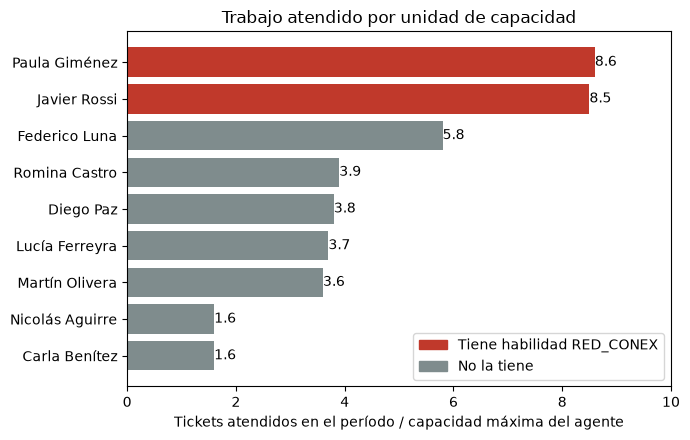

In [8]:
c = carga.sort_values("tickets_por_capacidad")
colores = ["#c0392b" if red else "#7f8c8d" for red in c["atiende_red"]]

fig, ax = plt.subplots(figsize=(7, 4.5))
barras = ax.barh(c.index, c["tickets_por_capacidad"], color=colores)
ax.bar_label(barras, fmt="%.1f")
ax.set_xlim(0, 10)
ax.set_xlabel("Tickets atendidos en el período / capacidad máxima del agente")
ax.set_title("Trabajo atendido por unidad de capacidad")
ax.legend(handles=[Patch(color="#c0392b", label="Tiene habilidad RED_CONEX"),
                   Patch(color="#7f8c8d", label="No la tiene")], loc="lower right")
plt.tight_layout()
plt.show()

**Interpretación.** La ocupación **actual** no es el problema: ningún agente pasa del 50 % de su capacidad. Lo que se ve es una
distribución desigual del trabajo acumulado: **Paula Giménez (8,6) y Javier Rossi (8,5)** atendieron claramente más tickets por
unidad de capacidad que el resto (8,6 y 8,5 contra 1,6 a 5,8), y son además los de menor capacidad máxima (5 y 4). Son los **únicos dos agentes con la
habilidad `RED_CONEX`**, y también los de mayor incumplimiento (37,2 % y 47,1 %, contra 17,2 % a 25,7 % en los demás).

### ¿Es un problema de las personas o de la categoría?

In [9]:
# Cada fila es un agente y una categoría; permite comparar a Javier Rossi en red contra su trabajo en hardware.
detalle = (vigentes[vigentes["agente"].isin(["Paula Giménez", "Javier Rossi"])]
           .groupby(["agente", "categoria"])
           .agg(tickets=("numero", "count"), incumplidos=("incumplido", "sum"), satisfaccion_prom=("puntaje", "mean")).round(2))
detalle["pct_incumplimiento"] = (detalle["incumplidos"] / detalle["tickets"] * 100).round(1)
detalle

tickets  incumplidos  satisfaccion_prom  \
agente        categoria                                            
Javier Rossi  HW_FALLA         8            1               3.75   
              RED_CONEX       26           15               2.60   
Paula Giménez RED_CONEX       43           16               2.39   

                         pct_incumplimiento  
agente        categoria                      
Javier Rossi  HW_FALLA                 12.5  
              RED_CONEX                57.7  
Paula Giménez RED_CONEX                37.2

Javier Rossi incumple **15 de 26** tickets de red (57,7 %) pero **1 de 8** en hardware (12,5 %), lo que sugiere que el incumplimiento
acompaña a la categoría y a su volumen, no a la persona. Paula Giménez solo atiende red. Es una asociación observada en estos datos,
no una prueba de causalidad.

## 5. Conclusión y recomendación

`RED_CONEX` es el punto crítico: el peor cumplimiento de SLA (44,9 %), la peor satisfacción (2,44) y los plazos más exigentes, y su
atención depende de solo dos agentes que además tienen la menor capacidad del equipo. Mientras tanto, otros agentes trabajan muy por debajo de
su capacidad (Carla Benítez y Nicolás Aguirre, 1,6 tickets por unidad de capacidad).

**Decisión propuesta: redistribuir y ampliar, no contratar.**

1. **Habilitar `RED_CONEX` en al menos dos agentes más**, empezando por los de menor uso relativo de su capacidad (Carla Benítez y Nicolás Aguirre),
   para que las derivaciones de red no recaigan solo en Paula y Javier.
2. **Dedicar a Javier Rossi a red**, derivando sus 8 tickets de hardware a agentes con la habilidad `HW_FALLA` y capacidad libre (Diego Paz, Lucía Ferreyra, Martín Olivera).
3. **Revisar los plazos de `RED_CONEX`** (1/4/12/24 h): es la categoría más rápida y aun así la que más incumple, así que conviene decidir si el compromiso es realista.

Alcance: los datos de prueba se generaron con patrones deliberados (entrega 1), por lo que la conclusión vale para este conjunto de datos y no se extrapola a una operación real.